# 04 · Mô hình xG riêng của Messi và kiểm tra lại H3

**Câu hỏi:** nếu Messi ở PSG vẫn dứt điểm như ở Barca, anh sẽ ghi được bao nhiêu bàn từ chính những cú sút đó?

**Thiết kế**

1. **Huấn luyện** mô hình xG trên các cú sút **không phải penalty** của Messi ở Barca. Mô hình học được Messi ở Barca
   biến từng loại cơ hội thành bàn thường xuyên đến mức nào.
2. **Thẩm định** mô hình bằng **cross-validation theo mùa ngay trong dữ liệu Barca**. Không dùng PSG làm tập kiểm
   tra, vì theo H3 Messi ở PSG dứt điểm khác. Nếu mô hình sai ở PSG, ta sẽ không biết đó là lỗi mô hình hay là H3 đúng.
3. **Áp dụng** mô hình cho các cú sút ở PSG như một *kịch bản giả định*, rồi so sánh với số bàn thật, có kèm khoảng
   tin cậy.

**Mốc so sánh chính:** Barca 2018-21, giống `03_hypothesis_testing.ipynb`. Toàn bộ thời gian ở Barca dùng để kiểm tra
độ vững của kết quả.

Mô hình (đặc trưng và pipeline Logistic Regression) giữ nguyên từ phiên bản đầu của notebook. Những gì thay đổi được
liệt kê ở cuối notebook.

## 0. Thiết lập

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = next(
    folder for folder in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
    if (folder / "src" / "eda_utils.py").exists()
)
sys.path.insert(0, str(PROJECT_ROOT))

from src.eda_utils import (
    PERIOD_COLORS, GOAL_COLOR, MISS_COLOR, TEXT_SECONDARY, AXIS_COLOR, apply_plot_style, load_data,
)
from src.hypothesis_tests import BASELINE_PERIOD, PSG_PERIOD
from src.xg_model import (
    FEATURES, NUMERIC_FEATURES, CATEGORICAL_FEATURES, BOOLEAN_FEATURES, REFERENCE_CATEGORIES, TARGET,
    prepare_model_data, fit_xg_model, predict_xg, cross_validated_predictions, coefficient_table,
    evaluate_predictions, bootstrap_auc_difference, calibration_table,
    simulate_counterfactual_goals, summarize_counterfactual,
)

warnings.filterwarnings("ignore", category=FutureWarning)
# Rare categories (e.g. Backheel, 1 shot) can be missing from a training fold; they are encoded as 0 on purpose.
warnings.filterwarnings("ignore", message="Found unknown categories")
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)
apply_plot_style()

PREDICTIONS_FILE = PROJECT_ROOT / "data" / "results" / "xg_model_predictions.csv"

## 1. Dữ liệu

Dùng bảng cú sút đã làm sạch (`messi_league_shots.csv`). Bảng này đã có sẵn khoảng cách và góc sút, nên không cần tính
lại. Penalty bị loại vì Messi không đá quả nào ở PSG, và vì xG của penalty gần như cố định.

| Nhóm đặc trưng | Cột |
|---|---|
| Vị trí sút | `distance_to_goal`, `shot_angle_deg` |
| Kiểu cú sút | `body_part`, `shot_type`, `technique` |
| Bối cảnh | `first_time`, `under_pressure` |

In [2]:
matches, shots = load_data(PROJECT_ROOT)
model_data = prepare_model_data(shots)

barca_shots = model_data[model_data["competition"] == "LaLiga"].reset_index(drop=True)
late_barca_shots = barca_shots[barca_shots["period"] == BASELINE_PERIOD].reset_index(drop=True)
psg_shots = model_data[model_data["period"] == PSG_PERIOD].reset_index(drop=True)

display(model_data.groupby("period", observed=True).agg(
    shots=(TARGET, "size"), goals=(TARGET, "sum"), statsbomb_npxg=("xg", "sum")))

,shots,goals,statsbomb_npxg
period,,,
Barca 2004-18,1768,333,216.024
Barca 2018-21,510,79,49.518
PSG 2021-23,218,22,23.130


## 2. Thẩm định mô hình trong dữ liệu Barca

**Cross-validation theo mùa (5 phần):** chia 17 mùa ở Barca thành 5 nhóm. Mỗi lần huấn luyện trên 4 nhóm và dự đoán
cho nhóm còn lại, nên mỗi cú sút được dự đoán bởi một mô hình **chưa từng thấy mùa giải của nó**. Chia theo mùa thay
vì chia ngẫu nhiên để các cú sút cùng một mùa không vừa nằm trong tập huấn luyện vừa nằm trong tập kiểm tra.

Hai câu hỏi cần trả lời:

- **Xếp hạng (ROC-AUC):** mô hình có phân biệt được cơ hội dễ và khó không?
- **Độ chuẩn (calibration):** khi mô hình nói "20%", có đúng khoảng 20% số cú sút đó thành bàn không? Với kịch bản
  giả định ở mục 4, **đây là điều quan trọng nhất**, vì ta cộng các xác suất lại thành số bàn kỳ vọng.

In [3]:
cv_predictions = cross_validated_predictions(barca_shots)
barca_shots["cv_xg"] = cv_predictions

evaluation = pd.DataFrame({
    "Mô hình Messi (cross-validation)": evaluate_predictions(barca_shots[TARGET], cv_predictions),
    "StatsBomb xG": evaluate_predictions(barca_shots[TARGET], barca_shots["xg"]),
}).T
display(evaluation)

auc_low, auc_high = bootstrap_auc_difference(barca_shots[TARGET], cv_predictions, barca_shots["xg"])
print(f"Chênh lệch AUC (mô hình Messi − StatsBomb): 95% CI {auc_low:+.3f} đến {auc_high:+.3f}")

print("\nSố bàn dự đoán (cross-validation) so với thực tế, theo giai đoạn:")
display(barca_shots.groupby("period", observed=True).agg(
    predicted_goals=("cv_xg", "sum"), actual_goals=(TARGET, "sum"), statsbomb_npxg=("xg", "sum")))

,roc_auc,brier,log_loss,predicted_goals,actual_goals
Mô hình Messi (cross-validation),0.735,0.129,0.414,412.262,412.0
StatsBomb xG,0.772,0.127,0.414,265.542,412.0


Chênh lệch AUC (mô hình Messi − StatsBomb): 95% CI -0.055 đến -0.021

Số bàn dự đoán (cross-validation) so với thực tế, theo giai đoạn:


,predicted_goals,actual_goals,statsbomb_npxg
period,,,
Barca 2004-18,331.899,333,216.024
Barca 2018-21,80.363,79,49.518


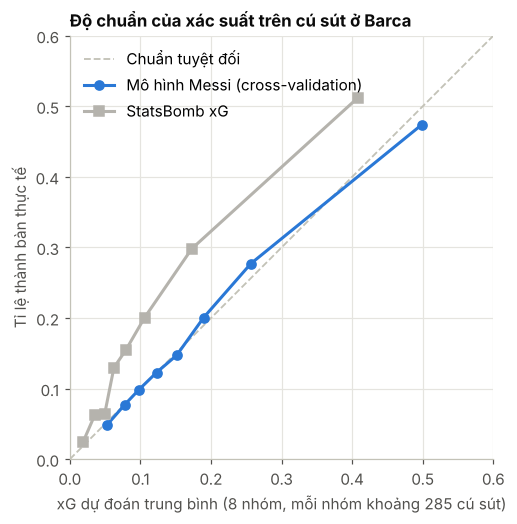

In [4]:
model_calibration = calibration_table(barca_shots[TARGET], cv_predictions)
statsbomb_calibration = calibration_table(barca_shots[TARGET], barca_shots["xg"])

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot([0, 0.6], [0, 0.6], linestyle="--", color=AXIS_COLOR, linewidth=1.2, label="Chuẩn tuyệt đối")
ax.plot(model_calibration["mean_predicted"], model_calibration["goal_rate"], marker="o",
        color=GOAL_COLOR, label="Mô hình Messi (cross-validation)")
ax.plot(statsbomb_calibration["mean_predicted"], statsbomb_calibration["goal_rate"], marker="s",
        color=MISS_COLOR, label="StatsBomb xG")
ax.set_xlim(0, 0.6)
ax.set_ylim(0, 0.6)
ax.set_aspect("equal")
ax.set_xlabel("xG dự đoán trung bình (8 nhóm, mỗi nhóm khoảng 285 cú sút)")
ax.set_ylabel("Tỉ lệ thành bàn thực tế")
ax.set_title("Độ chuẩn của xác suất trên cú sút ở Barca")
ax.legend(loc="upper left")
plt.show()

**Kết quả thẩm định**

- **Xếp hạng:** StatsBomb tốt hơn (AUC 0,772 so với 0,735; khoảng tin cậy của chênh lệch không chứa 0). Điều này dễ
  hiểu: StatsBomb dùng nhiều thông tin hơn, như vị trí thủ môn và hậu vệ, và được huấn luyện trên hàng trăm nghìn
  cú sút.
- **Độ chuẩn:** mô hình Messi chuẩn gần như tuyệt đối, kể cả ở những mùa nó chưa từng thấy. Mô hình dự đoán 412 bàn
  (thực tế 412), và riêng giai đoạn Barca 2018-21 là 80 bàn (thực tế 79). Trên biểu đồ, các điểm nằm sát đường chéo.
- **StatsBomb xG thấp hơn thực tế rất nhiều ở Barca** (266 so với 412 bàn): đó là mức của một cầu thủ trung bình, còn
  Messi ở Barca dứt điểm vượt xa mức đó. Đường StatsBomb nằm hẳn trên đường chéo.

Như vậy mô hình **không cần xếp hạng tốt hơn StatsBomb**. Điều nó cần là đại diện đúng cho "Messi ở Barca", và nó làm
được điều đó. Vì vậy có thể dùng nó làm mốc so sánh cho PSG.

## 3. Mô hình học được gì

Huấn luyện mô hình chính trên các cú sút ở Barca 2018-21. **Odds ratio** = exp(hệ số): lớn hơn 1 thì tăng khả năng
ghi bàn, nhỏ hơn 1 thì giảm.

Hai lưu ý khi đọc:

- Mỗi loại cú sút được so với trường hợp phổ biến nhất của Messi: **sút chân trái, tình huống bóng sống, kỹ thuật
  thường**.
- Khoảng cách và góc sút tính **theo mỗi 1 độ lệch chuẩn**, còn các biến khác tính **có so với không**. Hai loại này
  có đơn vị khác nhau, nên độ dài thanh **không** cho biết biến nào "quan trọng hơn".

,feature,coefficient,odds_ratio,scale
0,body_part_Head,-1.108,0.330,có so với không
1,distance_to_goal,-0.519,0.595,mỗi 1 độ lệch chuẩn
2,technique_Volley,-0.374,0.688,có so với không
3,body_part_Other,-0.332,0.718,có so với không
4,technique_Half Volley,-0.240,0.786,có so với không
5,body_part_Right Foot,-0.154,0.858,có so với không
6,technique_Diving Header,-0.126,0.882,có so với không
7,technique_Overhead Kick,-0.112,0.894,có so với không
8,under_pressure,-0.065,0.937,có so với không
9,first_time,0.150,1.162,có so với không


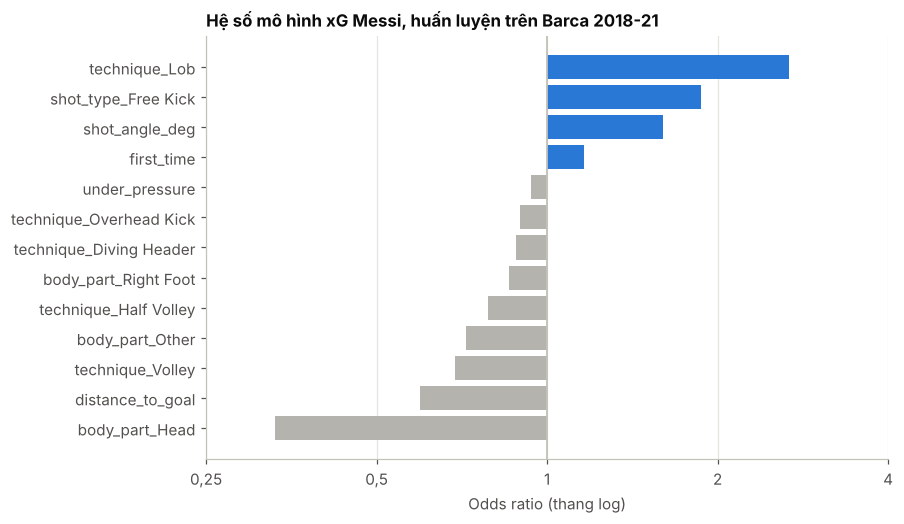

In [5]:
baseline_model = fit_xg_model(late_barca_shots)
coefficients = coefficient_table(baseline_model)
display(coefficients)

fig, ax = plt.subplots(figsize=(8, 5))
colors = np.where(coefficients["odds_ratio"] >= 1, GOAL_COLOR, MISS_COLOR)
ax.barh(coefficients["feature"], coefficients["odds_ratio"] - 1, left=1, color=colors)
ax.axvline(1, color=AXIS_COLOR, linewidth=1.2)
ax.set_xscale("log")
ax.minorticks_off()
ax.set_xticks([0.25, 0.5, 1, 2, 4], ["0,25", "0,5", "1", "2", "4"])
ax.set_xlabel("Odds ratio (thang log)")
ax.set_title(f"Hệ số mô hình xG Messi, huấn luyện trên {BASELINE_PERIOD}")
ax.grid(axis="y", visible=False)
plt.show()

**Đọc kết quả**

- Càng xa khung thành, xác suất ghi bàn càng giảm; góc sút càng rộng, xác suất càng tăng. Đây là hai yếu tố cơ bản
  của mọi mô hình xG.
- **Đánh đầu** có odds chỉ bằng khoảng 1/3 so với sút chân trái ở cùng vị trí.
- **Sút phạt trực tiếp** có odds cao hơn bóng sống ở cùng khoảng cách (khoảng 1,9 lần): Messi sút phạt rất tốt, và
  khi đá phạt không ai gây áp lực.
- **Lốp bóng** có odds cao (khoảng 2,7 lần), nhưng chỉ dựa trên vài chục cú sút, nên con số này không chắc chắn.

## 4. Áp dụng cho PSG: kiểm tra lại H3

**Kịch bản giả định:** mô hình dự đoán xác suất ghi bàn cho từng cú sút ở PSG *nếu Messi vẫn dứt điểm như ở Barca*.
Cộng các xác suất lại được số bàn kỳ vọng.

**Khoảng tin cậy** gồm hai nguồn bất định, mô phỏng 500 lần:

1. **Bất định của mô hình:** mỗi lần huấn luyện lại trên một mẫu bootstrap của các cú sút ở Barca.
2. **May rủi khi dứt điểm:** mỗi cú sút được tung đồng xu với xác suất bằng xG dự đoán.

Nếu Messi ở PSG vẫn dứt điểm như ở Barca, số bàn thật (22) phải nằm trong khoảng mô phỏng.

In [6]:
counterfactual_rows = []
simulations = {}
for label, train in [(BASELINE_PERIOD, late_barca_shots), ("Barca 2004-21 (kiểm tra độ vững)", barca_shots)]:
    simulations[label] = simulate_counterfactual_goals(train, psg_shots)
    counterfactual_rows.append(summarize_counterfactual(label, train, psg_shots, simulations[label]))

counterfactual = pd.DataFrame(counterfactual_rows).set_index("training_data")
counterfactual.loc["StatsBomb xG (cầu thủ trung bình)", ["expected_goals", "actual_goals"]] = [
    psg_shots["xg"].sum(), psg_shots[TARGET].sum()]
display(counterfactual)

,train_shots,expected_goals,interval_low,interval_high,actual_goals,p_at_most_actual
training_data,,,,,,
Barca 2018-21,510.0,36.717,23.0,50.000,22.0,0.024
Barca 2004-21 (kiểm tra độ vững),2278.0,36.582,27.0,48.525,22.0,0.002
StatsBomb xG (cầu thủ trung bình),NaN,23.130,NaN,NaN,22.0,NaN


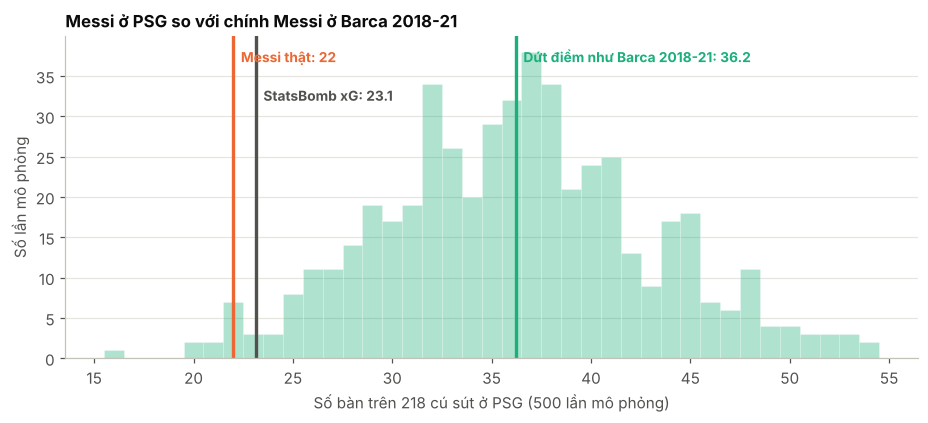

In [7]:
main_simulation = simulations[BASELINE_PERIOD]
actual_goals = int(psg_shots[TARGET].sum())
statsbomb_goals = psg_shots["xg"].sum()

fig, ax = plt.subplots(figsize=(10, 3.8))
bins = np.arange(main_simulation.min(), main_simulation.max() + 2) - 0.5
ax.hist(main_simulation, bins=bins, color=PERIOD_COLORS[BASELINE_PERIOD], alpha=0.35, edgecolor="white", linewidth=0.5)
for value, color, text, height in [
    (actual_goals, PERIOD_COLORS[PSG_PERIOD], f"Messi thật: {actual_goals}", 0.92),
    (statsbomb_goals, TEXT_SECONDARY, f"StatsBomb xG: {statsbomb_goals:.1f}", 0.80),
    (main_simulation.mean(), PERIOD_COLORS[BASELINE_PERIOD], f"Dứt điểm như Barca 2018-21: {main_simulation.mean():.1f}", 0.92),
]:
    ax.axvline(value, color=color, linewidth=2.2)
    ax.annotate(text, xy=(value, ax.get_ylim()[1] * height), xytext=(5, 0), textcoords="offset points",
                color=color, fontweight="bold", fontsize=9)
ax.set_xlabel("Số bàn trên 218 cú sút ở PSG (500 lần mô phỏng)")
ax.set_ylabel("Số lần mô phỏng")
ax.set_title("Messi ở PSG so với chính Messi ở Barca 2018-21")
ax.grid(axis="x", visible=False)
plt.show()

**Kết quả**

- Nếu dứt điểm như ở Barca 2018-21, Messi sẽ ghi khoảng **37 bàn** từ 218 cú sút ở PSG (khoảng 95%: **23–50 bàn**).
  Thực tế anh ghi **22 bàn**, thấp hơn khoảng 15 bàn.
- Xác suất một "Messi ở Barca" chỉ ghi ≤ 22 bàn từ những cú sút này là khoảng **2%**. Khi huấn luyện trên toàn bộ thời
  gian ở Barca, kết quả gần như giống hệt (khoảng 37 bàn, xác suất < 1%). Như vậy kết quả không phụ thuộc vào việc
  chọn mốc so sánh.
- Số bàn thật (22) lại rất sát StatsBomb xG (23,1): ở PSG, Messi dứt điểm **như một cầu thủ trung bình**.

**H3 được xác nhận bằng một cách thứ hai**, độc lập với hồi quy logistic trong `03_hypothesis_testing.ipynb` (odds
ratio 0,49). Hai phương pháp cho cùng một kết luận.

## 5. Xuất kết quả cho Power BI

Chỉ xuất `shot_id` và xG theo mô hình Messi, để nối vào bảng cú sút sẵn có trong Power BI qua `shot_id` (quan hệ
1–1). Không tạo thêm một bảng cú sút thứ hai.

- `xg_messi_barca`: xác suất ghi bàn nếu Messi dứt điểm như ở Barca 2018-21 (mô hình chính). Với cú sút ở Barca
  2018-21, đây là dự đoán trên chính dữ liệu huấn luyện.
- `xg_messi_cv`: dự đoán cross-validation cho các cú sút ở Barca. Dùng cột này khi muốn so sánh mô hình với thực tế ở
  Barca.

In [8]:
predictions = model_data[["shot_id"]].copy()
predictions["xg_messi_barca"] = predict_xg(baseline_model, model_data).round(4)
predictions = predictions.merge(barca_shots[["shot_id", "cv_xg"]].rename(columns={"cv_xg": "xg_messi_cv"}),
                                on="shot_id", how="left")
predictions["xg_messi_cv"] = predictions["xg_messi_cv"].round(4)

PREDICTIONS_FILE.parent.mkdir(parents=True, exist_ok=True)
predictions.to_csv(PREDICTIONS_FILE, index=False)
print(f"Đã lưu {len(predictions)} dòng vào {PREDICTIONS_FILE.relative_to(PROJECT_ROOT)}")
display(predictions.head())

Đã lưu 2496 dòng vào data/results/xg_model_predictions.csv


,shot_id,xg_messi_barca,xg_messi_cv
0,1,0.113,0.103
1,2,0.137,0.158
2,3,0.389,0.299
3,4,0.038,0.039
4,5,0.066,0.070


## 6. Kết luận

- Mô hình xG riêng của Messi **chuẩn rất tốt trên dữ liệu Barca** (dự đoán 412 bàn, thực tế 412, kiểm tra theo từng
  mùa chưa thấy). Khả năng xếp hạng cơ hội kém StatsBomb, nhưng điều đó không ảnh hưởng tới mục đích của mô hình.
- Áp dụng cho PSG: một "Messi ở Barca" sẽ ghi khoảng **37 bàn (23–50)** từ những cú sút đó, trong khi thực tế là
  **22 bàn**. **H3 được xác nhận**, khớp với kết quả ở notebook 03.

**Hạn chế**

- Mô hình cho thấy Messi ở PSG dứt điểm kém hơn Messi ở Barca, nhưng **không cho biết vì sao**: do tuổi, do đồng đội
  hay do lối chơi mới (xem H4 trong notebook 03).
- Mô hình chỉ biết vị trí và kiểu cú sút, không biết vị trí thủ môn và hậu vệ. Nếu ở PSG Messi sút trong tình huống
  bị kèm chặt hơn, một phần của "dứt điểm kém hơn" có thể thực chất là "cơ hội khó hơn".
- Chỉ có 218 cú sút ở PSG, nên khoảng tin cậy rộng (23–50 bàn).

**Khác với phiên bản đầu**

| Phiên bản đầu | Phiên bản này | Lý do |
|---|---|---|
| Thẩm định bằng PSG | Cross-validation theo mùa trong dữ liệu Barca | PSG khác Barca chính là điều H3 muốn kiểm tra |
| Có tính penalty | Không tính penalty | Đồng bộ với notebook 02–03 (Messi không đá penalty ở PSG) |
| Huấn luyện trên toàn bộ La Liga | Barca 2018-21 làm chính, toàn bộ Barca để kiểm tra độ vững | Đồng bộ mốc so sánh với notebook 03 |
| Chỉ có một con số kỳ vọng (36,6 bàn) | Thêm khoảng tin cậy và xác suất | Để kết luận có căn cứ thống kê |
| Danh mục tham chiếu theo thứ tự chữ cái (Backheel, Head, Free Kick) | Danh mục phổ biến nhất (chân trái, bóng sống, kỹ thuật thường) | Để odds ratio dễ đọc |
| Đọc `data/raw`, tự tính khoảng cách và góc | Đọc `messi_league_shots.csv` | Tránh tính lại, tránh lệch tên giải |
| Xuất `CuSut.csv` (một bảng cú sút thứ hai) | Xuất `xg_model_predictions.csv` theo `shot_id` | Power BI chỉ có một bảng cú sút |
| Shot map, đường ROC | Bỏ shot map (đã có trong EDA); thay ROC bằng biểu đồ độ chuẩn | Với kịch bản giả định, độ chuẩn quan trọng hơn khả năng xếp hạng |